# DSCI 552 — Homework 6
**Matthew Hall**

## 1. Tree-Based Methods

### 1(a). Load the APS Failure Dataset

The supplied training and test sets contain 60,000 and 16,000 observations, respectively. Each observation has 170 numerical predictors and a class label. The positive class represents failures related to the Air Pressure System (APS), while the negative class represents failures unrelated to the APS. Missing values are encoded as `na` and are loaded as `NaN`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

def load_aps(filename):
    path = Path("/content") / filename

    with path.open() as f:
        header_row = next(
            i for i, line in enumerate(f)
            if line.strip().startswith("class,")
        )

    return pd.read_csv(path, skiprows=header_row, na_values="na")

train = load_aps("aps_failure_training_set.csv")
test = load_aps("aps_failure_test_set.csv")

print("Training shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())
display(train["class"].value_counts())

Training shape: (60000, 171)
Test shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


,count
class,
neg,59000
pos,1000


### 1(b)(i). Missing Values and Imputation

Common approaches to missing data include deleting incomplete observations, replacing missing values with a feature's mean or median, using nearest-neighbor imputation, and predicting missing values from other features through iterative imputation.

Here, 59,409 of the 60,000 training observations, or approximately 99.0%, contain at least one missing value. Deleting all incomplete observations would therefore discard almost the entire training set. Some features also have very high missingness; for example, approximately 82.1% of `br_000` is missing.

I use median imputation because it is computationally efficient and less sensitive to extreme values than mean imputation. However, replacing many observations with the same median can distort distributions and relationships, especially for features with substantial missingness.

The imputer is fitted using only the training data and then applied to the test data. This differs from the assignment's footnote suggesting test-set statistics; training-set statistics preserve a fixed preprocessing rule for future observations. During cross-validation, the imputer is fitted separately within each training fold.

In [2]:
from sklearn.impute import SimpleImputer

# Separate predictors and labels; pos = 1 and neg = 0.
X_train = train.drop(columns="class")
X_test = test.drop(columns="class")

y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})

# Summarize missing values before imputation.
missing_summary = pd.DataFrame({
    "Missing count": X_train.isna().sum(),
    "Missing percent": X_train.isna().mean() * 100
}).sort_values("Missing percent", ascending=False)

print(
    "Training rows with at least one missing value:",
    X_train.isna().any(axis=1).sum()
)
display(missing_summary.head(15))

# Learn medians from training data and apply them to both sets.
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing training values after imputation:",
      X_train_imputed.isna().sum().sum())
print("Missing test values after imputation:",
      X_test_imputed.isna().sum().sum())

Training rows with at least one missing value: 59409


,Missing count,Missing percent
br_000,49264,82.106667
bq_000,48722,81.203333
bp_000,47740,79.566667
bo_000,46333,77.221667
ab_000,46329,77.215000
cr_000,46329,77.215000
bn_000,44009,73.348333
bm_000,39549,65.915000
bl_000,27277,45.461667
bk_000,23034,38.390000


Missing training values after imputation: 0
Missing test values after imputation: 0


### 1(b)(ii). Coefficient of Variation

For each of the 170 features, I calculate

$$
CV=\frac{s}{m},
$$

where $s$ is the sample standard deviation, calculated with `ddof=1`, and $m$ is the sample mean. These calculations use the median-imputed training data.

The highest CV values occur for `cf_000`, `co_000`, and `ad_000`. Large CV values indicate substantial variation relative to the mean, which can arise from extreme observations or features concentrated near zero. A high CV does not necessarily imply that a feature is useful for predicting APS failure. The feature `cd_000` is constant after imputation and has a CV of zero.

In [3]:
# Calculate CV using the imputed training data.
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Sample standard deviation": feature_stds,
    "CV": feature_stds / feature_means.replace(0, np.nan)
}).sort_values("CV", ascending=False)

# Show all 170 features.
with pd.option_context("display.max_rows", 170):
    display(cv_table)

# Select floor(sqrt(170)) = 13 features for visualization later.
n_selected = int(np.sqrt(X_train_imputed.shape[1]))
top_cv_features = cv_table["CV"].dropna().head(n_selected).index.tolist()

print(f"\nTop {n_selected} features by CV:")
print(top_cv_features)
print("\nFeatures with undefined CV:",
      cv_table["CV"].isna().sum())

,Mean,Sample standard deviation,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
dj_000,3.727133e+01,4.379166e+03,117.494225
ag_000,2.191577e+02,2.036364e+04,92.917755
as_000,1.254079e+02,1.095219e+04,87.332500
ay_009,1.149620e+03,9.741156e+04,84.733735
ak_000,9.076607e+02,7.299859e+04,80.424975



Top 13 features by CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']

Features with undefined CV: 0


### 1(b)(iii). Correlation Matrix

The heatmap displays Pearson correlations among all 170 imputed training features. Several blocks show strong positive correlations, suggesting that groups of features contain overlapping information. Strong negative correlations are less prominent.

The blank row and column correspond to `cd_000`. Its standard deviation is zero, so its Pearson correlations are undefined. Because these correlations use imputed data, they describe the relationships after median imputation.

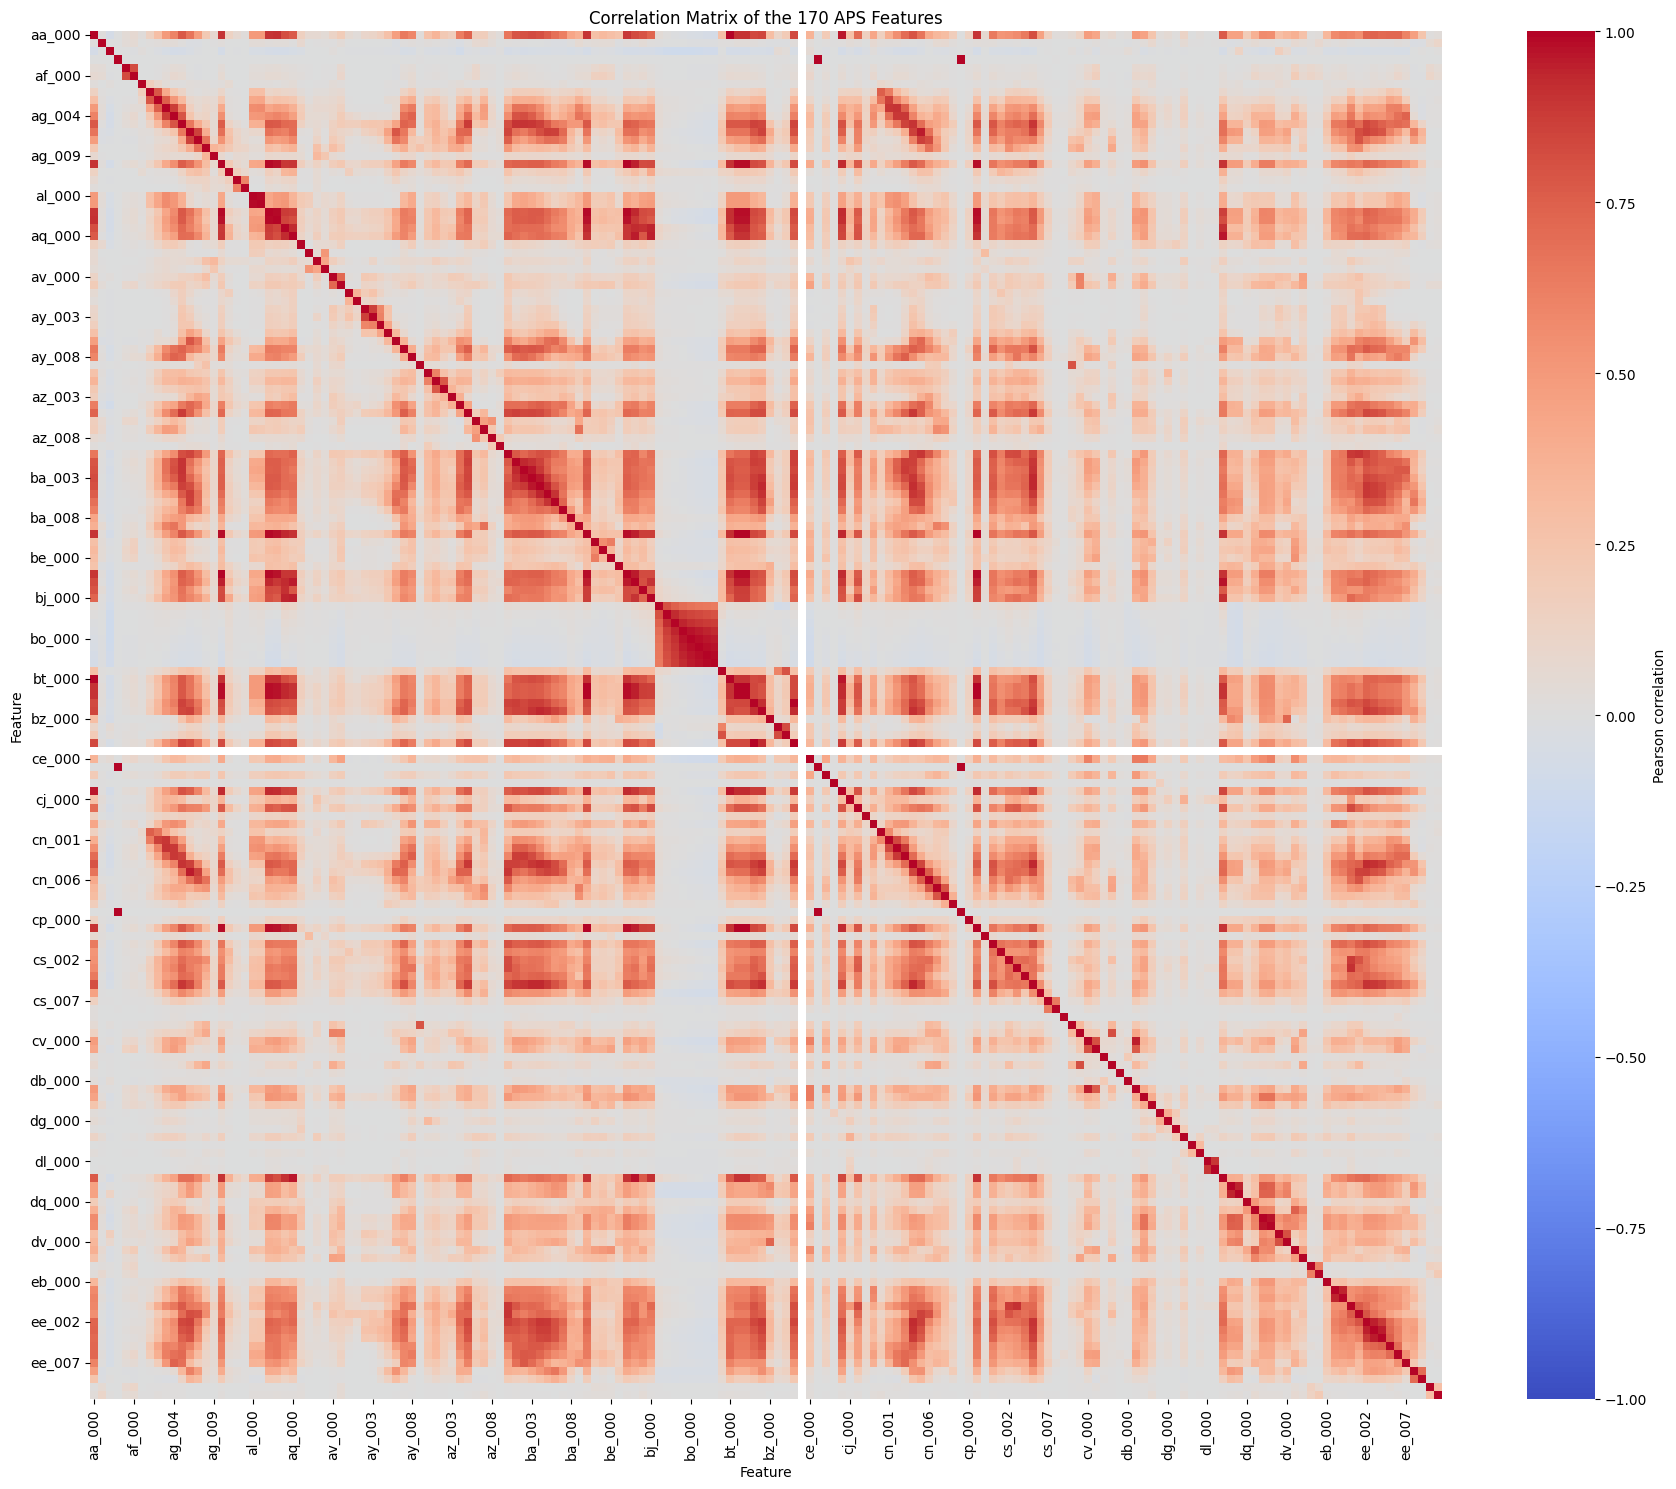

Constant features: ['cd_000']


In [4]:
# Pearson correlations using the imputed training data.
correlation_matrix = X_train_imputed.corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=5,
    yticklabels=5,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Matrix of the 170 APS Features")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(
    "Constant features:",
    X_train_imputed.columns[
        X_train_imputed.nunique() <= 1
    ].tolist()
)

### 1(b)(iv). Scatter Plots and Box Plots

I select the $\lfloor\sqrt{170}\rfloor=13$ features with the highest CV values for visualization. All 170 predictors remain available for the classification models.

The selected features are `cf_000`, `co_000`, `ad_000`, `cs_009`, `dh_000`, `dj_000`, `ag_000`, `as_000`, `ay_009`, `ak_000`, `az_009`, `ch_000`, and `au_000`.

I plot $\log(1+x)$ values because extreme values would otherwise compress most observations near zero. This transformation is used only for visualization.

The scatter plots show substantial overlap between the classes. The box plots suggest some differences in the distributions of `cf_000`, `co_000`, and `ad_000`, but none clearly separates the classes on its own. Many other selected features are concentrated at zero, causing their boxes to collapse into horizontal lines while nonzero values appear as outliers. The class imbalance also makes positive observations harder to distinguish in the scatter plots.

These plots can suggest potentially useful patterns, but they cannot establish statistical significance or determine a feature's predictive contribution after accounting for other predictors.

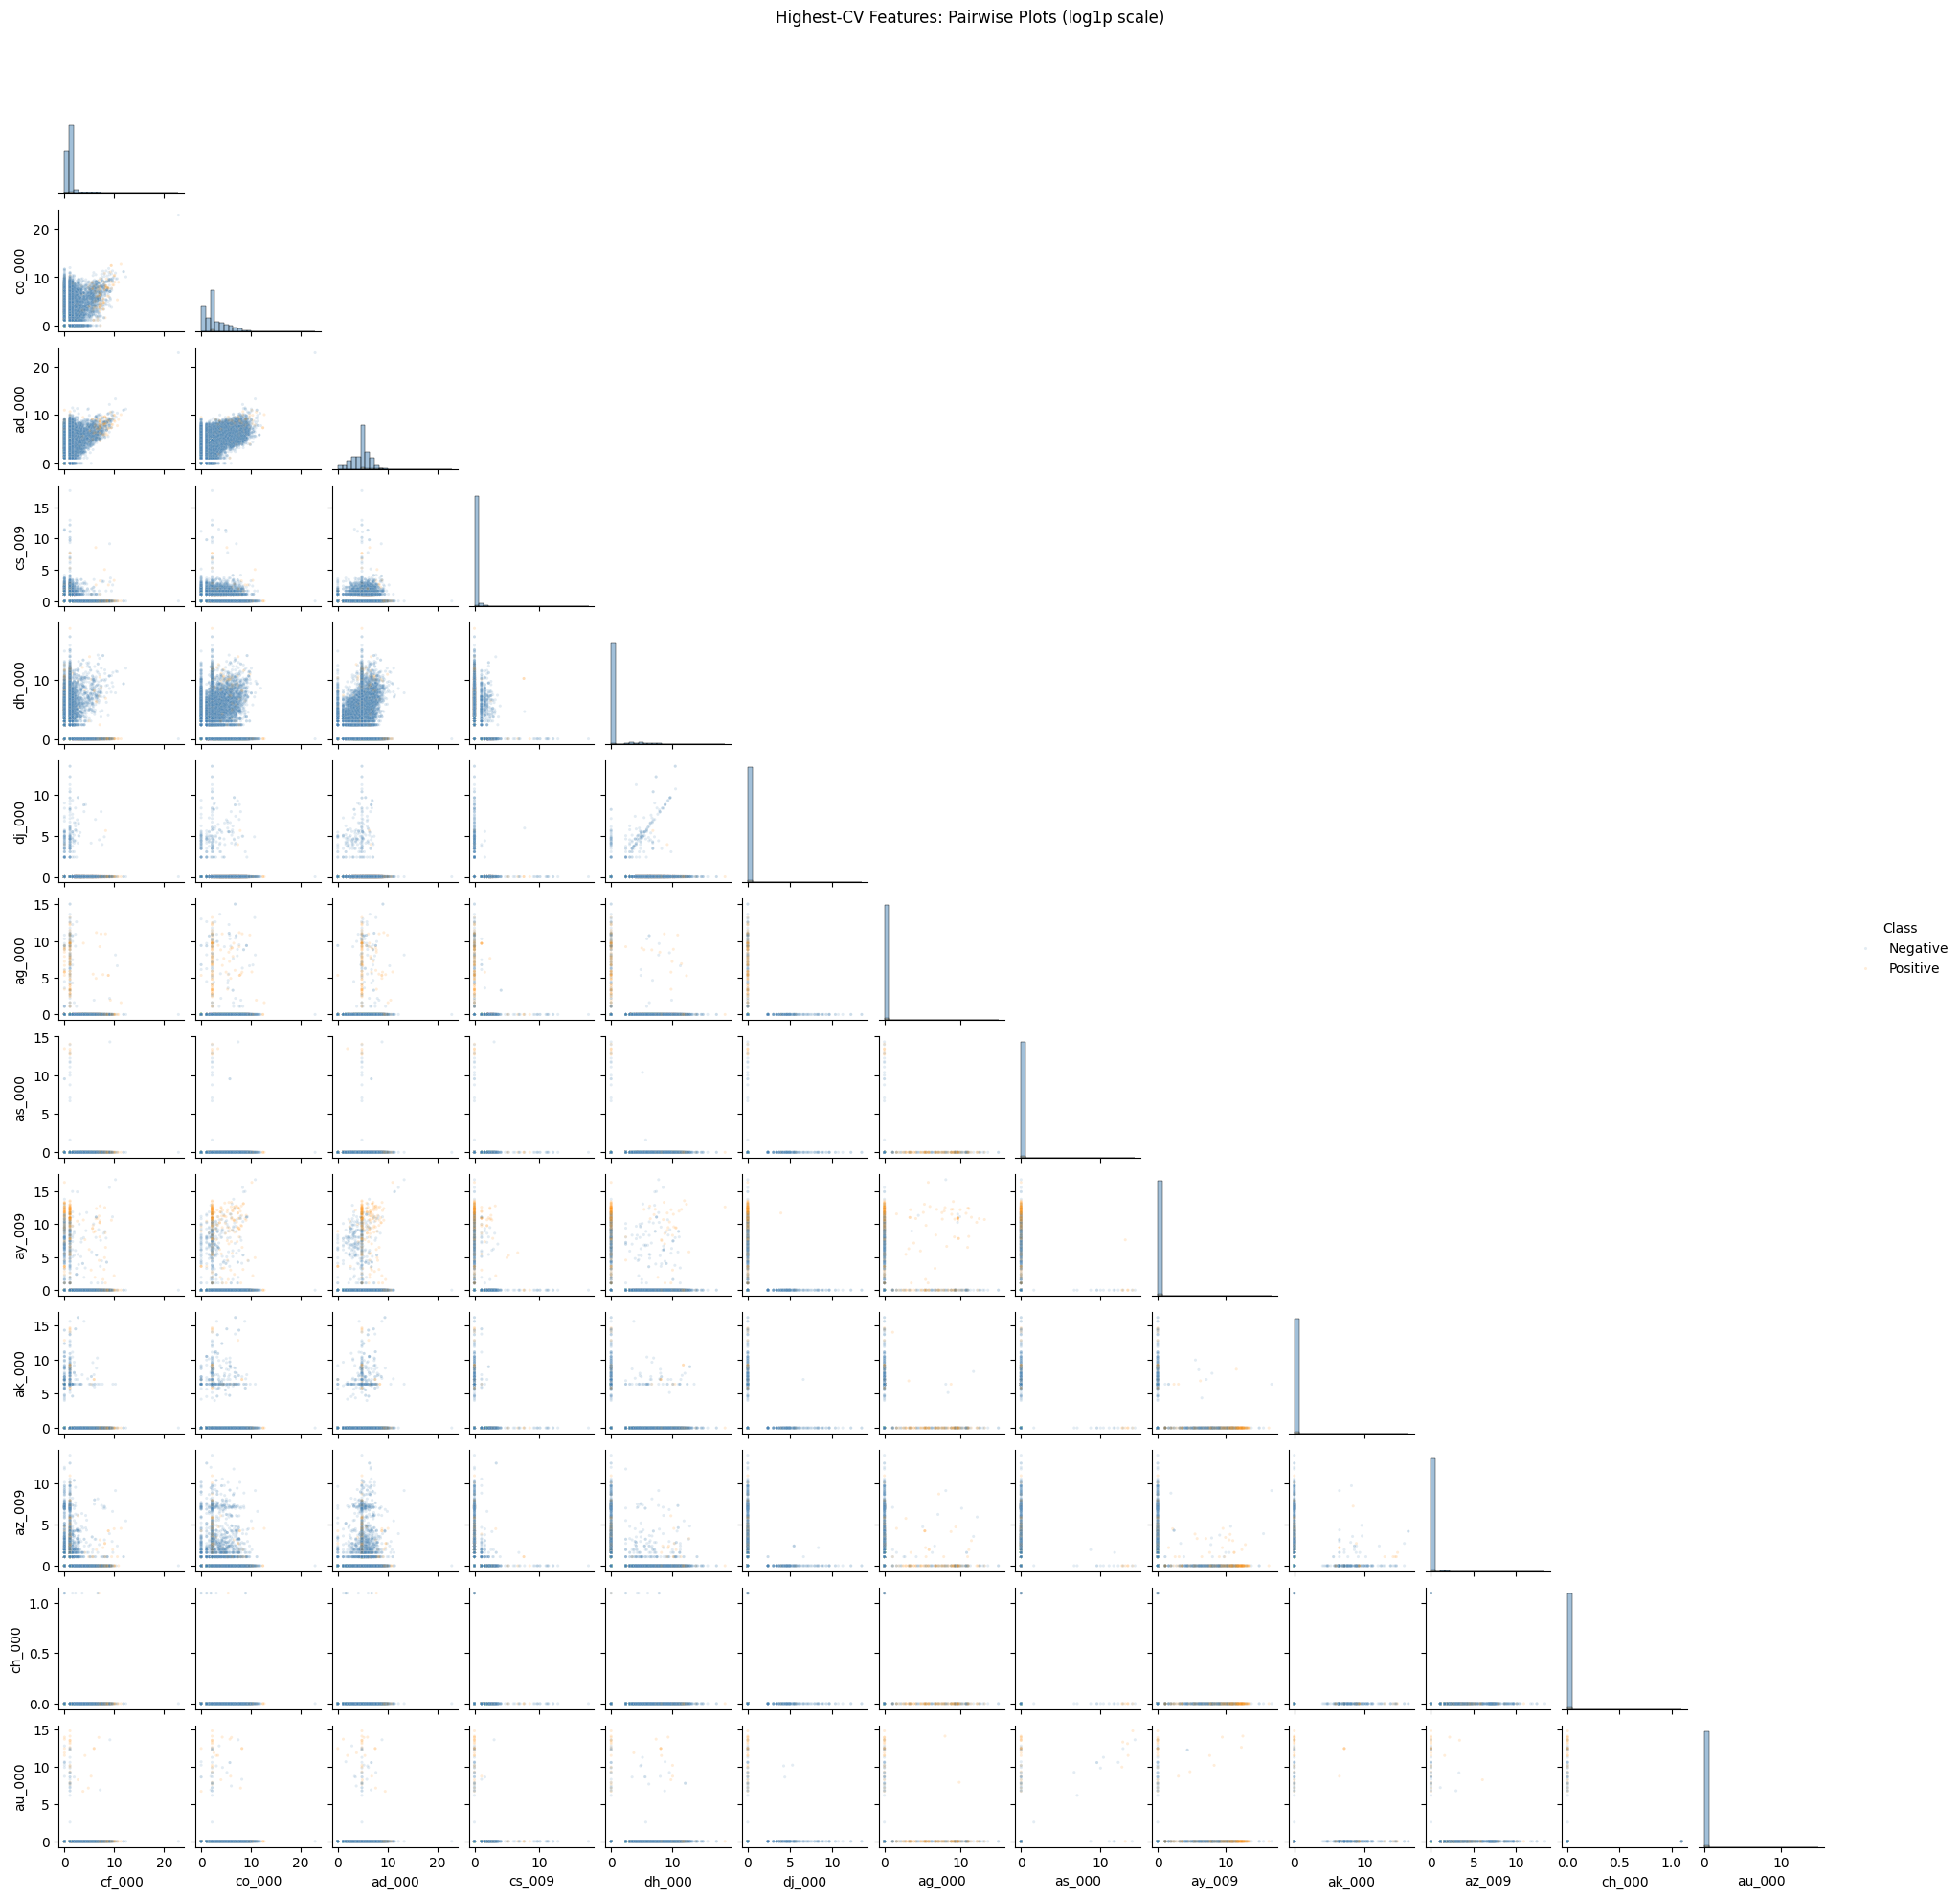

In [5]:
# Log transformation for visualization only.
plot_data = np.log1p(X_train_imputed[top_cv_features])
plot_data["Class"] = train["class"].map({
    "neg": "Negative",
    "pos": "Positive"
})

palette = {"Negative": "steelblue", "Positive": "darkorange"}

# Pairwise scatter plots for all 13 selected features.
g = sns.pairplot(
    plot_data,
    hue="Class",
    hue_order=["Negative", "Positive"],
    palette=palette,
    corner=True,
    diag_kind="hist",
    height=1.5,
    plot_kws={"s": 5, "alpha": 0.15, "rasterized": True},
    diag_kws={"bins": 25}
)

g.fig.suptitle(
    "Highest-CV Features: Pairwise Plots (log1p scale)",
    y=1.02
)
plt.show()

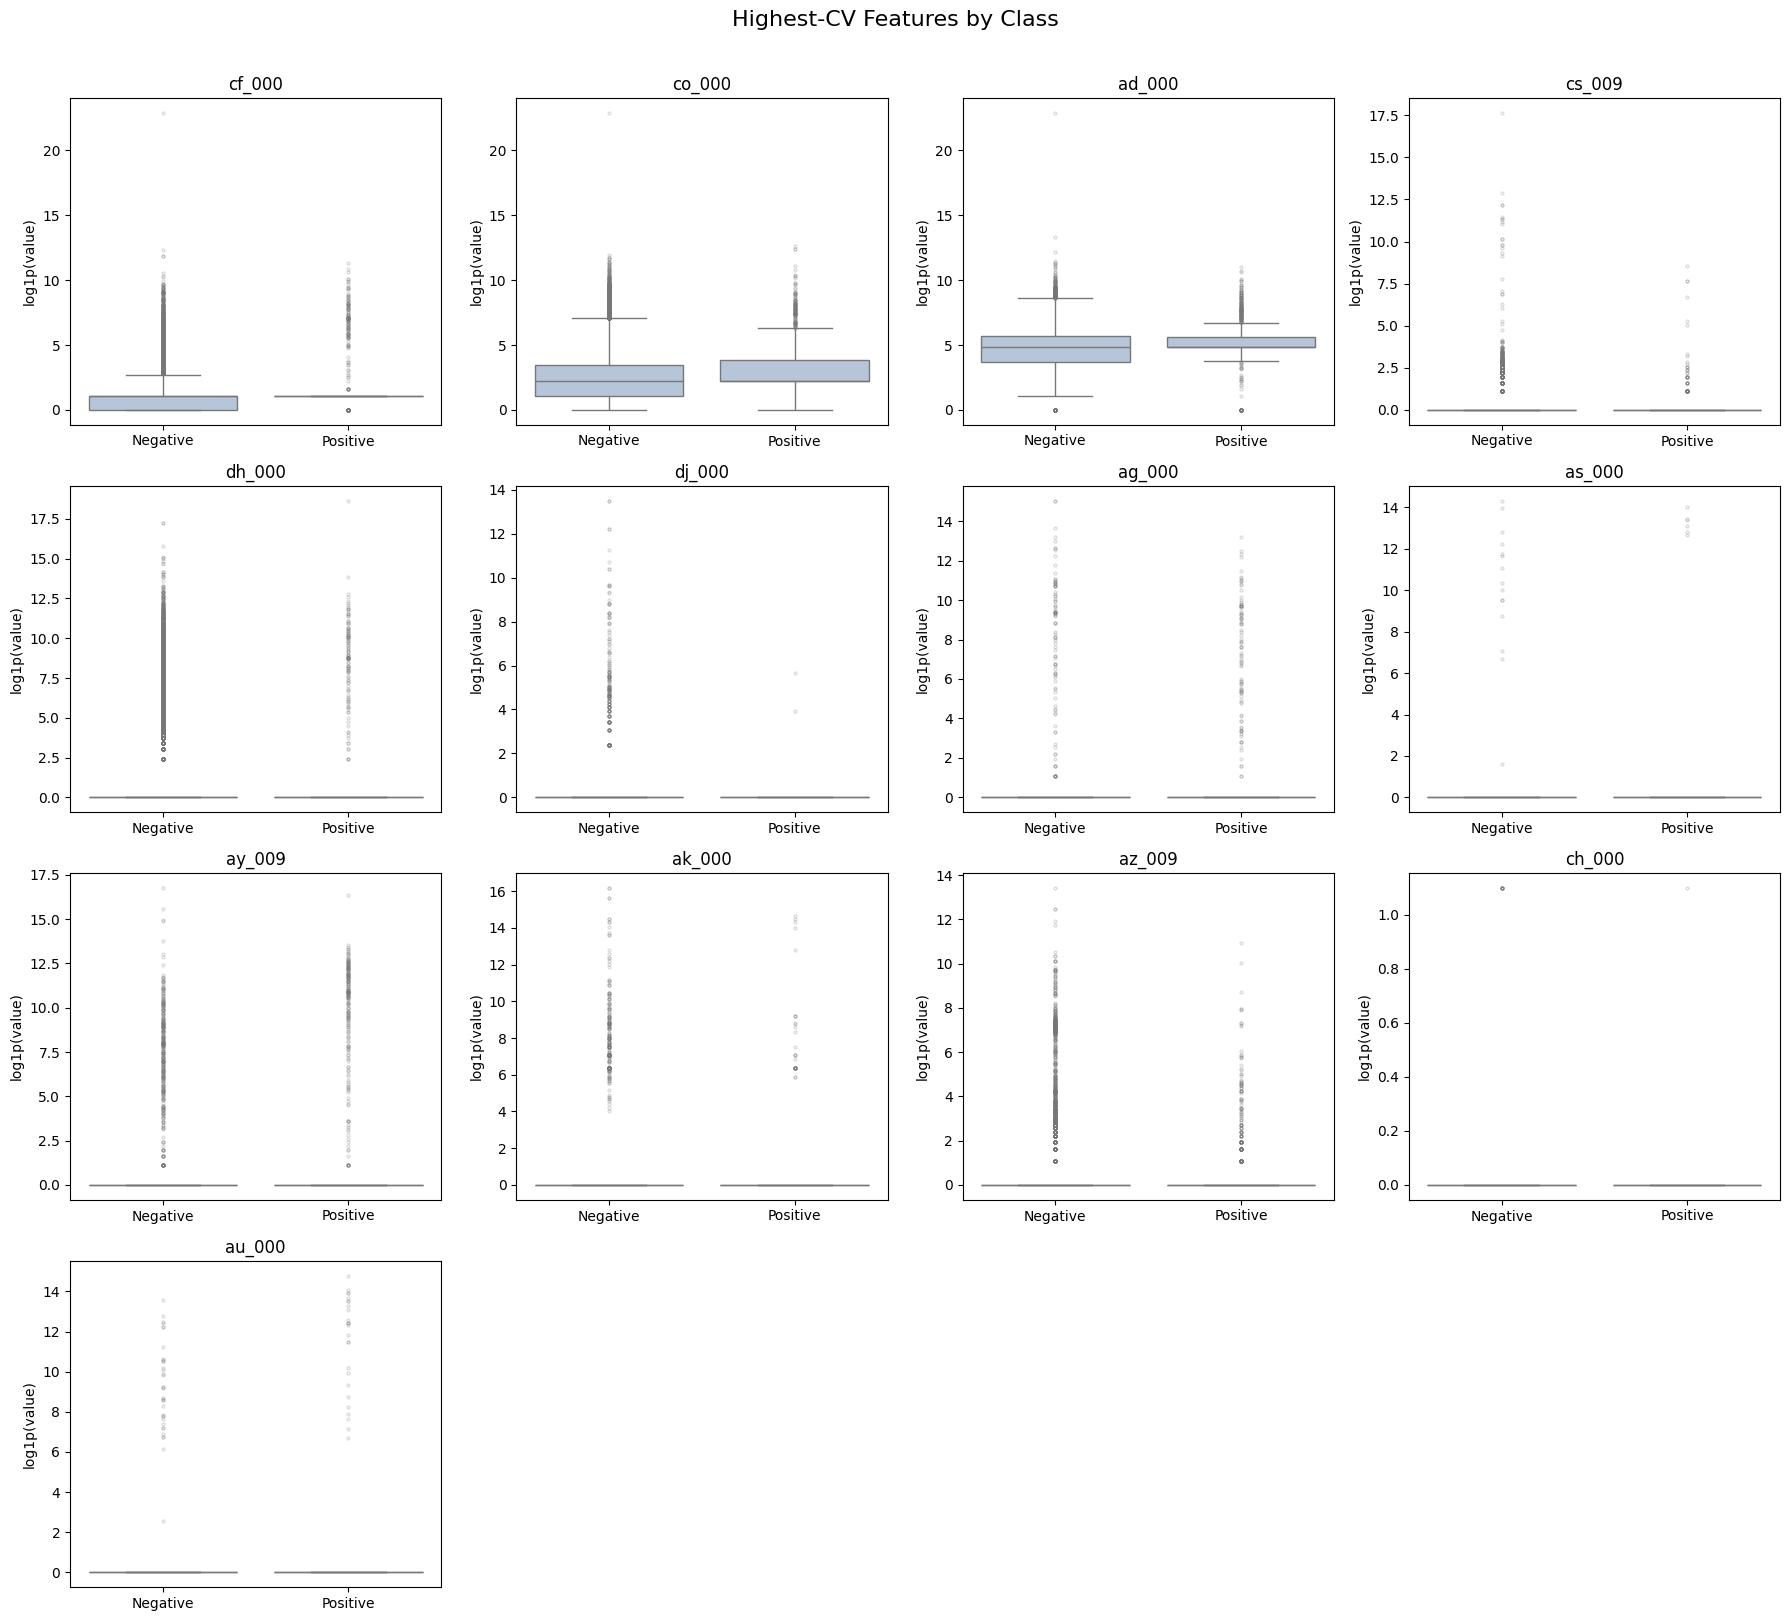

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.ravel()

for ax, feature in zip(axes, top_cv_features):
    sns.boxplot(
        data=plot_data,
        x="Class",
        y=feature,
        order=["Negative", "Positive"],
        color="lightsteelblue",
        flierprops={"markersize": 2, "alpha": 0.25},
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("log1p(value)")

for ax in axes[len(top_cv_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Highest-CV Features by Class",
    fontsize=16,
    y=1.01
)
plt.tight_layout()
plt.show()

### 1(b)(v). Class Imbalance

The training set contains 59,000 negative observations and 1,000 positive observations. Thus, 98.33% are negative and 1.67% are positive, giving a negative-to-positive ratio of 59:1.

The test set contains 15,625 negative observations and 375 positive observations, corresponding to 97.66% negative and 2.34% positive.

Both sets are strongly imbalanced. A classifier that always predicts negative would achieve 98.33% training accuracy while failing to detect every positive case. Therefore, I examine positive-class recall and confusion matrices alongside overall misclassification rates and ROC AUC.

In [7]:
class_counts = pd.DataFrame({
    "Training count": train["class"].value_counts(),
    "Test count": test["class"].value_counts()
}).reindex(["neg", "pos"])

class_counts["Training percent"] = (
    class_counts["Training count"] / len(train) * 100
)
class_counts["Test percent"] = (
    class_counts["Test count"] / len(test) * 100
)

display(class_counts.round(3))

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Training negative-to-positive ratio: {ratio:.0f}:1")
print(f"Always-negative training error: {y_train.mean():.4%}")

,Training count,Test count,Training percent,Test percent
class,,,,
neg,59000,15625,98.333,97.656
pos,1000,375,1.667,2.344


Training negative-to-positive ratio: 59:1
Always-negative training error: 1.6667%


### 1(c). Random Forest Without Imbalance Compensation

I fit a random forest with 300 trees, square-root feature sampling, bootstrap sampling, and no class weights. Predictions use the default classification threshold.

The forest achieves zero training misclassification and a training AUC of 1. Its test misclassification rate is 0.7563%, and its test AUC is 0.9942. On the test set, it correctly identifies 272 of the 375 positive cases, giving a positive recall of 72.53%. It produces 18 false positives and 103 false negatives.

The OOB error estimate is 0.5733%, approximately 0.1829 percentage points below the test error. Thus, OOB error slightly underestimates the observed test error. The higher positive-class proportion in the test set may also contribute to differences between the two error rates.

Although overall test error is low, the model misses 27.47% of positive cases. This illustrates why overall accuracy alone is insufficient for this dataset.

The OOB estimate is approximate because median imputation was fitted to the full training set before the forest was trained, rather than separately within each tree's bootstrap sample.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_auc_score,
    RocCurveDisplay
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight=None,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_imputed, y_train)

print("Random forest training complete.")

Random forest training complete.


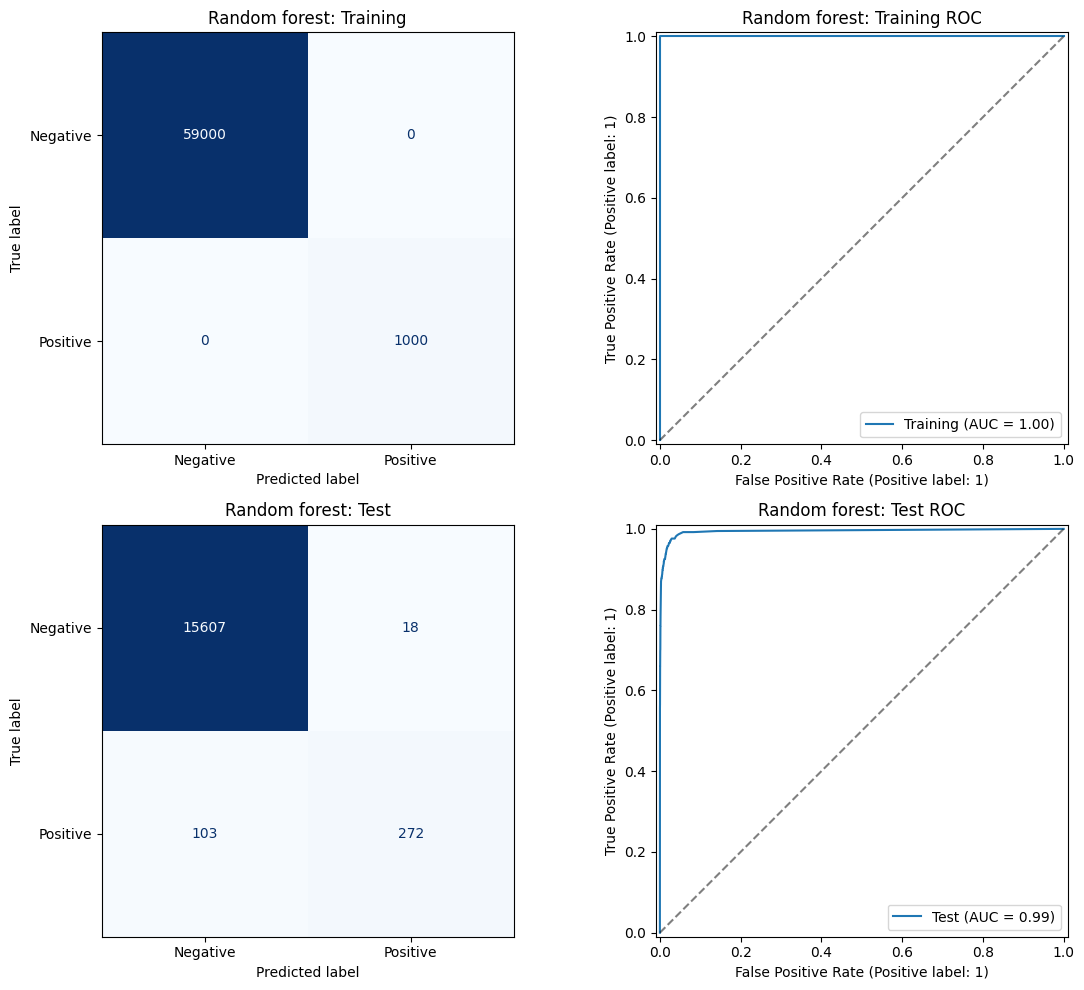

,Model,Set,Misclassification rate,AUC,Positive recall,TN,FP,FN,TP
0,Random forest,Training,0.000000,1.000000,1.000000,59000,0,0,1000
1,Random forest,Test,0.007563,0.994226,0.725333,15607,18,103,272


OOB error estimate: 0.5733%
Test error:         0.7563%
Test minus OOB:     0.1829%


In [11]:
def evaluate_classifier(model, X_train_eval, X_test_eval,
                        y_train, y_test, model_name):
    datasets = [
        ("Training", X_train_eval, y_train),
        ("Test", X_test_eval, y_test)
    ]

    results = []
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    for row, (split, X, y) in enumerate(datasets):
        predictions = model.predict(X)
        probabilities = model.predict_proba(X)[:, 1]

        cm = confusion_matrix(y, predictions, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()

        results.append({
            "Model": model_name,
            "Set": split,
            "Misclassification rate": 1 - accuracy_score(y, predictions),
            "AUC": roc_auc_score(y, probabilities),
            "Positive recall": tp / (tp + fn),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Negative", "Positive"]
        ).plot(ax=axes[row, 0], cmap="Blues", colorbar=False)

        axes[row, 0].set_title(f"{model_name}: {split}")

        RocCurveDisplay.from_predictions(
            y,
            probabilities,
            name=split,
            ax=axes[row, 1]
        )
        axes[row, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
        axes[row, 1].set_title(f"{model_name}: {split} ROC")

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results)


rf_results = evaluate_classifier(
    rf,
    X_train_imputed,
    X_test_imputed,
    y_train,
    y_test,
    "Random forest"
)

display(rf_results)

rf_oob_error = 1 - rf.oob_score_
rf_test_error = rf_results.loc[
    rf_results["Set"] == "Test", "Misclassification rate"
].iloc[0]

print(f"OOB error estimate: {rf_oob_error:.4%}")
print(f"Test error:         {rf_test_error:.4%}")
print(f"Test minus OOB:     {rf_test_error - rf_oob_error:.4%}")

### 1(d). Random Forest With Imbalance Compensation

Class imbalance can be addressed through class weighting, majority-class undersampling, or minority-class oversampling. Here, I use `class_weight="balanced"`, which weights observations inversely to their class frequencies. Each positive training observation receives 59 times the weight of each negative observation. The other forest settings remain unchanged.

The weighted forest again has zero training error and a training AUC of 1. On the test set, its misclassification rate is 1.0875%, its AUC is 0.9933, and its positive recall is 57.60%. It produces 15 false positives and 159 false negatives.

Compared with the unweighted forest, weighting eliminates only 3 false positives while introducing 56 additional false negatives. Its OOB error is 0.7883%, which underestimates its test error by approximately 0.2992 percentage points.

Therefore, this weighting approach does not improve performance in this experiment. Class weighting changes how the trees are fitted, but it does not guarantee better minority-class recall at the default classification threshold.

In [12]:
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight="balanced",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_balanced.fit(X_train_imputed, y_train)

print("Balanced random forest training complete.")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   51.3s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed:  3.5min finished


Balanced random forest training complete.


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.1s
[Parallel(n_jobs=2)]: Done 300 out of 300 | elapsed:    2.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.7s
[Parallel(n_jobs=2)]: Done 300 out of 300 | elapsed:    2.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done 300 out of 300 | elapsed:    0.4s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      |

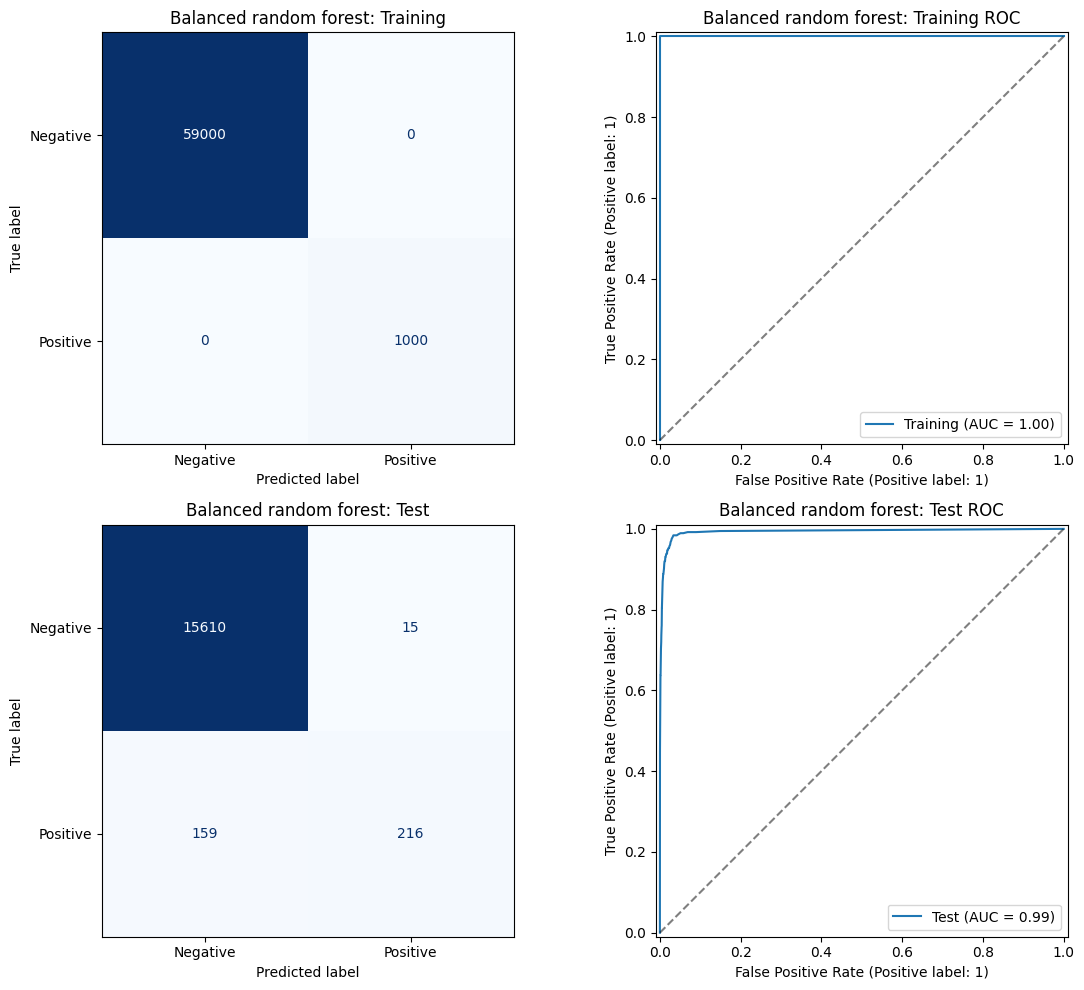

,Model,Set,Misclassification rate,AUC,Positive recall,TN,FP,FN,TP
0,Balanced random forest,Training,0.000000,1.000000,1.000,59000,0,0,1000
1,Balanced random forest,Test,0.010875,0.993252,0.576,15610,15,159,216


Balanced OOB error:  0.7883%
Balanced test error: 1.0875%
Test minus OOB:     0.2992%


,Model,Set,Misclassification rate,AUC,Positive recall,TN,FP,FN,TP
0,Random forest,Test,0.007563,0.994226,0.725333,15607,18,103,272
1,Balanced random forest,Test,0.010875,0.993252,0.576000,15610,15,159,216


In [13]:
rf_balanced_results = evaluate_classifier(
    rf_balanced,
    X_train_imputed,
    X_test_imputed,
    y_train,
    y_test,
    "Balanced random forest"
)

display(rf_balanced_results)

rf_balanced_oob_error = 1 - rf_balanced.oob_score_
rf_balanced_test_error = rf_balanced_results.loc[
    rf_balanced_results["Set"] == "Test",
    "Misclassification rate"
].iloc[0]

print(f"Balanced OOB error:  {rf_balanced_oob_error:.4%}")
print(f"Balanced test error: {rf_balanced_test_error:.4%}")
print(
    "Test minus OOB:     "
    f"{rf_balanced_test_error - rf_balanced_oob_error:.4%}"
)

# Compare the two forests on the test set.
rf_comparison = pd.concat(
    [
        rf_results.query("Set == 'Test'"),
        rf_balanced_results.query("Set == 'Test'")
    ],
    ignore_index=True
)

display(rf_comparison)

### 1(e). XGBoost Without Imbalance Compensation

The assignment describes logistic regression at individual tree nodes. Standard XGBoost's tree booster instead fits boosted decision trees using a binary logistic objective; it does not fit a separate logistic regression at each node. I use this tree-based XGBoost implementation and tune `reg_alpha`, the L1 regularization parameter on tree weights.

I use five-fold stratified cross-validation to compare alpha values of 0, 0.01, 0.1, 1, and 10. Alpha is selected by the lowest mean validation misclassification rate. Median imputation is fitted separately within each training fold, and no class weighting or resampling is applied. The model uses 300 boosting rounds, a maximum tree depth of 4, and a learning rate of 0.1.

Cross-validation selects alpha = 0.1, with a mean CV misclassification rate of 0.5517%. The final model has a training misclassification rate of 0.0383% and a training AUC of approximately 0.9999.

The test misclassification rate is 0.6125%, and the test AUC is 0.9952. The test confusion matrix contains 15,609 true negatives, 16 false positives, 82 false negatives, and 293 true positives. Positive recall is 78.13%.

Test error exceeds CV error by approximately 0.0608 percentage points. The selected model's CV error may be somewhat optimistic because the same folds were used to choose alpha; the separate test set provides an additional evaluation.

Compared with the original random forest, XGBoost has lower test error, slightly higher AUC, and higher positive recall.

In [14]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=300,
        max_depth=4,
        learning_rate=0.1,
        reg_lambda=1,
        scale_pos_weight=1,  # No imbalance compensation
        random_state=42,
        n_jobs=2
    ))
])

alpha_grid = {
    "model__reg_alpha": [0, 0.01, 0.1, 1, 10]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=alpha_grid,
    scoring={
        "accuracy": "accuracy",
        "auc": "roc_auc"
    },
    refit="accuracy",
    cv=cv,
    n_jobs=1,
    verbose=2,
    return_train_score=False,
    error_score="raise"
)

# Use original predictors so imputation is fitted within each fold.
xgb_search.fit(X_train, y_train)

print("XGBoost cross-validation and final training complete.")
print("Selected alpha:", xgb_search.best_params_["model__reg_alpha"])
print(f"Selected model's mean CV error: {1 - xgb_search.best_score_:.4%}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END .................................model__reg_alpha=0; total time=  34.5s
[CV] END .................................model__reg_alpha=0; total time=  15.3s
[CV] END .................................model__reg_alpha=0; total time=  16.0s
[CV] END .................................model__reg_alpha=0; total time=  16.5s
[CV] END .................................model__reg_alpha=0; total time=  16.3s
[CV] END ..............................model__reg_alpha=0.01; total time=  15.3s
[CV] END ..............................model__reg_alpha=0.01; total time=  15.5s
[CV] END ..............................model__reg_alpha=0.01; total time=  15.4s
[CV] END ..............................model__reg_alpha=0.01; total time=  15.2s
[CV] END ..............................model__reg_alpha=0.01; total time=  15.1s
[CV] END ...............................model__reg_alpha=0.1; total time=  16.7s
[CV] END ...............................model__re

,Alpha,Mean CV error,CV error SD,Mean CV AUC
2,0.10,0.005517,0.000392,0.987550
3,1.00,0.005567,0.000378,0.988785
0,0.00,0.005633,0.000464,0.988200
1,0.01,0.005700,0.000581,0.987837
4,10.00,0.007417,0.000693,0.989204


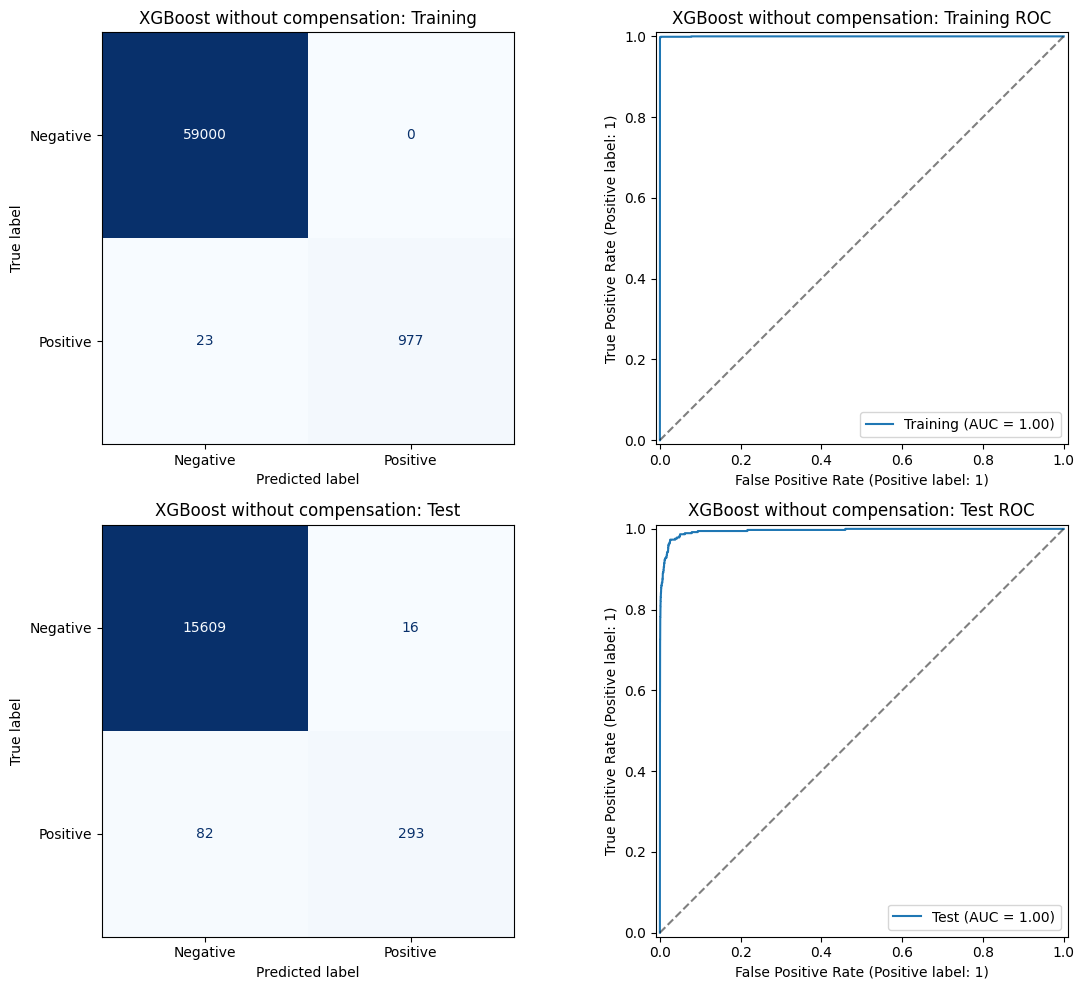

,Model,Set,Misclassification rate,AUC,Positive recall,TN,FP,FN,TP
0,XGBoost without compensation,Training,0.000383,0.999918,0.977000,59000,0,23,977
1,XGBoost without compensation,Test,0.006125,0.995172,0.781333,15609,16,82,293


Mean CV error:  0.5517%
Test error:     0.6125%
Test minus CV:  0.0608%


In [15]:
xgb_cv_results = pd.DataFrame({
    "Alpha": [
        params["model__reg_alpha"]
        for params in xgb_search.cv_results_["params"]
    ],
    "Mean CV error": (
        1 - xgb_search.cv_results_["mean_test_accuracy"]
    ),
    "CV error SD": xgb_search.cv_results_["std_test_accuracy"],
    "Mean CV AUC": xgb_search.cv_results_["mean_test_auc"]
})

display(xgb_cv_results.sort_values("Mean CV error"))

xgb_best = xgb_search.best_estimator_

# The pipeline applies its training-fitted imputer automatically.
xgb_results = evaluate_classifier(
    xgb_best,
    X_train,
    X_test,
    y_train,
    y_test,
    "XGBoost without compensation"
)

display(xgb_results)

xgb_cv_error = 1 - xgb_search.best_score_
xgb_test_error = xgb_results.loc[
    xgb_results["Set"] == "Test",
    "Misclassification rate"
].iloc[0]

print(f"Mean CV error:  {xgb_cv_error:.4%}")
print(f"Test error:     {xgb_test_error:.4%}")
print(f"Test minus CV:  {xgb_test_error - xgb_cv_error:.4%}")

### 1(f). XGBoost With SMOTE

SMOTE generates synthetic minority-class observations by interpolating between minority observations and their nearest minority-class neighbors. I apply SMOTE to balance the classes without discarding majority-class observations.

The pipeline first imputes missing values, then standardizes the predictors, applies SMOTE, and fits XGBoost. Standardization prevents features with large numerical units from dominating SMOTE's distance calculations. The XGBoost settings, candidate alpha values, cross-validation folds, and selection metric match part 1(e).

The correct cross-validation procedure applies imputation, scaling, and SMOTE separately within each training fold. The validation fold is transformed using the training-fitted preprocessing but is not resampled. Applying SMOTE before constructing the folds could allow validation observations to influence synthetic training observations and produce overly optimistic results.

After selecting alpha, the pipeline is refitted using the full training set. Balancing the full training set produces 59,000 observations per class, or 118,000 observations in total. Training metrics are evaluated on the original 60,000 training observations, and test metrics use the original 16,000 test observations. Neither evaluation set is resampled.

In [16]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        sampling_strategy="auto",
        k_neighbors=5,
        random_state=42
    )),
    ("model", clone(xgb_pipeline.named_steps["model"]))
])

smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=alpha_grid,
    scoring={
        "accuracy": "accuracy",
        "auc": "roc_auc"
    },
    refit="accuracy",
    cv=cv,
    n_jobs=1,
    verbose=2,
    return_train_score=False,
    error_score="raise"
)

# Original data: each fold independently fits its preprocessing and SMOTE.
smote_search.fit(X_train, y_train)

print("SMOTE + XGBoost cross-validation and final training complete.")
print("Selected alpha:", smote_search.best_params_["model__reg_alpha"])
print(f"Selected model's mean CV error: {1 - smote_search.best_score_:.4%}")

# Inspect how many synthetic observations the final fit generated.
smote_best = smote_search.best_estimator_
n_synthetic = sum(
    smote_best.named_steps["smote"].sampling_strategy_.values()
)

print("Synthetic training observations added:", n_synthetic)
print("Total training observations after SMOTE:", len(y_train) + n_synthetic)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END .................................model__reg_alpha=0; total time=  44.6s
[CV] END .................................model__reg_alpha=0; total time=  28.3s
[CV] END .................................model__reg_alpha=0; total time=  39.8s
[CV] END .................................model__reg_alpha=0; total time=  40.1s
[CV] END .................................model__reg_alpha=0; total time=  46.5s
[CV] END ..............................model__reg_alpha=0.01; total time=  40.3s
[CV] END ..............................model__reg_alpha=0.01; total time=  41.8s
[CV] END ..............................model__reg_alpha=0.01; total time=  41.4s
[CV] END ..............................model__reg_alpha=0.01; total time=  28.7s
[CV] END ..............................model__reg_alpha=0.01; total time=  39.1s
[CV] END ...............................model__reg_alpha=0.1; total time=  51.4s
[CV] END ...............................model__re

,Alpha,Mean CV error,CV error SD,Mean CV AUC
0,0.00,0.007817,0.000974,0.985749
2,0.10,0.007867,0.000995,0.986271
1,0.01,0.007867,0.000838,0.985992
3,1.00,0.007967,0.000702,0.986380
4,10.00,0.008783,0.000700,0.986996


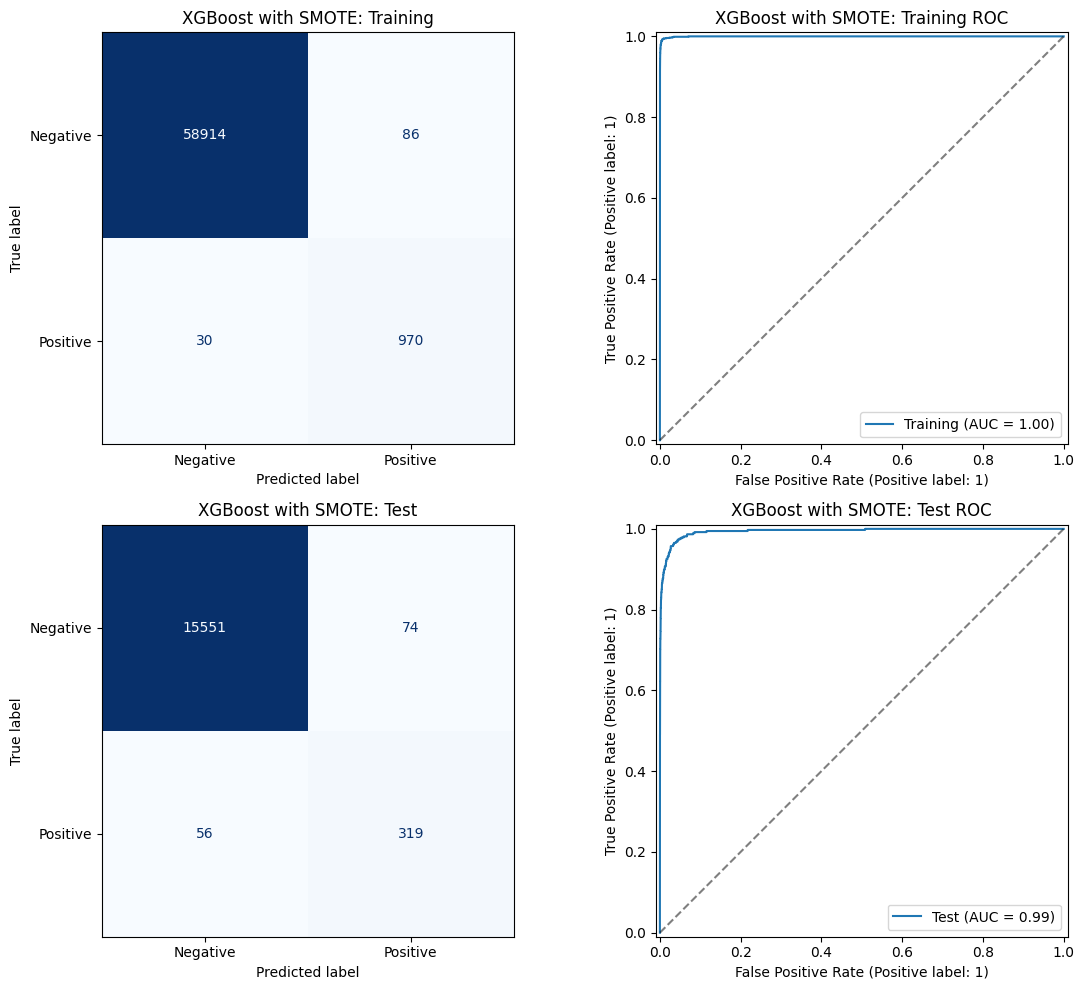

,Model,Set,Misclassification rate,AUC,Positive recall,TN,FP,FN,TP
0,XGBoost with SMOTE,Training,0.001933,0.999686,0.970000,58914,86,30,970
1,XGBoost with SMOTE,Test,0.008125,0.993994,0.850667,15551,74,56,319


Mean CV error: 0.7817%
Test error:    0.8125%
Test minus CV: 0.0308%


,Model,Set,Misclassification rate,AUC,Positive recall,TN,FP,FN,TP
0,Random forest,Test,0.007563,0.994226,0.725333,15607,18,103,272
1,Balanced random forest,Test,0.010875,0.993252,0.576000,15610,15,159,216
2,XGBoost without compensation,Test,0.006125,0.995172,0.781333,15609,16,82,293
3,XGBoost with SMOTE,Test,0.008125,0.993994,0.850667,15551,74,56,319


In [17]:
smote_cv_results = pd.DataFrame({
    "Alpha": [
        params["model__reg_alpha"]
        for params in smote_search.cv_results_["params"]
    ],
    "Mean CV error": (
        1 - smote_search.cv_results_["mean_test_accuracy"]
    ),
    "CV error SD": smote_search.cv_results_["std_test_accuracy"],
    "Mean CV AUC": smote_search.cv_results_["mean_test_auc"]
})

display(smote_cv_results.sort_values("Mean CV error"))

# Evaluate on the original training and test observations.
# The pipeline skips SMOTE when predicting.
smote_results = evaluate_classifier(
    smote_best,
    X_train,
    X_test,
    y_train,
    y_test,
    "XGBoost with SMOTE"
)

display(smote_results)

smote_cv_error = 1 - smote_search.best_score_
smote_test_error = smote_results.loc[
    smote_results["Set"] == "Test",
    "Misclassification rate"
].iloc[0]

print(f"Mean CV error: {smote_cv_error:.4%}")
print(f"Test error:    {smote_test_error:.4%}")
print(f"Test minus CV: {smote_test_error - smote_cv_error:.4%}")

all_test_results = pd.concat(
    [
        result.query("Set == 'Test'")
        for result in [
            rf_results,
            rf_balanced_results,
            xgb_results,
            smote_results
        ]
    ],
    ignore_index=True
)

display(all_test_results)

### SMOTE Results and Model Comparison

Cross-validation selects alpha = 0, giving a mean CV misclassification rate of 0.7817%. Thus, among the candidate values, no additional L1 penalty performs best after SMOTE.

On the original training observations, the misclassification rate is 0.1933%, AUC is 0.9997, and positive recall is 97.00%. On the test set, the misclassification rate is 0.8125%, AUC is 0.9940, and positive recall is 85.07%. The test confusion matrix contains 15,551 true negatives, 74 false positives, 56 false negatives, and 319 true positives.

Test error exceeds mean CV error by approximately 0.0308 percentage points. As in part 1(e), the selected model's CV error may be somewhat optimistic because these folds were also used to choose alpha.

Compared with uncompensated XGBoost, SMOTE increases positive recall from 78.13% to 85.07% and reduces missed failures from 82 to 56. However, false positives increase from 16 to 74, overall test error increases from 0.6125% to 0.8125%, and AUC decreases slightly from 0.9952 to 0.9940.

Therefore, SMOTE improves failure detection at the default threshold but does not improve overall misclassification or AUC. Uncompensated XGBoost has the lowest test error and highest test AUC among the four models, while SMOTE XGBoost has the highest positive recall.

The dataset description assigns a cost of 10 to a false positive and 500 to a false negative. Under this supplied cost metric, uncompensated XGBoost has test cost

$$
10(16)+500(82)=41{,}160,
$$

while SMOTE XGBoost has test cost

$$
10(74)+500(56)=28{,}740.
$$

Thus, despite its higher overall error, SMOTE produces a lower test cost under the dataset's stated penalties. This is a descriptive comparison; the test set was not used to tune alpha or the classification threshold.

## 2. ISLR 6.6.3

The constraint $\sum_{j=1}^{p}|\beta_j|\leq s$ controls the flexibility of the fitted model. At $s=0$, all slope coefficients are zero, so the model predicts a constant. Increasing $s$ relaxes the constraint.

**(a) Training RSS: iv. Steadily decrease.**

Increasing $s$ expands the set of allowed coefficient values. The previous solution remains feasible, so the minimum training RSS cannot increase. More precisely, training RSS is non-increasing: once the constraint allows a least-squares solution, it stays constant.

**(b) Test RSS: ii. Decrease initially, then eventually increase in a U shape.**

Initially, increasing flexibility can reduce underfitting and improve test predictions. With too much flexibility, the model can fit training noise and increase test RSS. This is the typical expected pattern, rather than a guarantee for every dataset.

**(c) Variance: iii. Steadily increase.**

As the constraint becomes less restrictive, the model generally becomes more sensitive to the particular training sample, increasing variance.

**(d) Squared bias: iv. Steadily decrease.**

Relaxing the constraint allows the model to better approximate the underlying relationship, generally reducing squared bias.

**(e) Irreducible error: v. Remain constant.**

Irreducible error comes from noise in the data-generating process. Changing the constraint does not change this noise.

## 3. ISLR 6.6.5

The two predictor columns are identical, and the variables are centered, so the intercept is zero. Let $x_i=x_{i1}=x_{i2}$. The fitted value for observation $i$ is therefore $x_i(\beta_1+\beta_2)$.

**(a) Ridge optimization problem**

The ridge estimates minimize

$$
\min_{\beta_1,\beta_2}
(y_1-x_{11}\beta_1-x_{12}\beta_2)^2
+(y_2-x_{21}\beta_1-x_{22}\beta_2)^2
+\lambda(\beta_1^2+\beta_2^2).
$$

Using the identical predictor columns, this becomes

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b) Why the ridge estimates are equal**

Let $t=\beta_1+\beta_2$. For a fixed $t$, the RSS is fixed. Also,

$$
\beta_1^2+\beta_2^2
=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
$$

For $\lambda>0$, the penalty is minimized when $\beta_1=\beta_2$. Therefore,

$$
\hat{\beta}_1=\hat{\beta}_2=\frac{\hat{t}}{2}.
$$

Ridge divides the combined coefficient equally between the identical predictors.

**(c) Lasso optimization problem**

The lasso estimates minimize

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|).
$$

**(d) Why the lasso estimates need not be unique**

For a fixed sum $t=\beta_1+\beta_2$, the triangle inequality gives

$$
|\beta_1|+|\beta_2|\geq|t|.
$$

Equality holds whenever the coefficients have the same sign, allowing either coefficient to be zero. Thus, if the optimal combined coefficient is $\hat{t}\neq0$, every pair

$$
(\hat{\beta}_1,\hat{\beta}_2)
=(a\hat{t},(1-a)\hat{t}),
\qquad 0\leq a\leq1,
$$

has the same fitted values and the same minimum penalty. For example, $(\hat{t},0)$, $(0,\hat{t})$, and $(\hat{t}/2,\hat{t}/2)$ are all solutions.

Therefore, lasso can assign different coefficients to identical predictors, while ridge assigns equal coefficients. One qualification is that if $\lambda>0$ is large enough to make $\hat{t}=0$, the unique solution is $(0,0)$.

## 4. ISLR 8.4.5

**Majority vote: Red.**

Six of the ten estimated probabilities exceed 0.5, so six trees predict Red and four predict Green. The majority vote therefore classifies the observation as Red.

**Average probability: Green.**

The average estimated probability of Red is

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=\frac{4.5}{10}
=0.45.
$$

Since the average probability of Red is below 0.5, this approach classifies the observation as Green.

The approaches differ because majority voting uses only each tree's predicted class, while probability averaging also accounts for how strongly each tree favors a class.

## 5. ISLR 9.7.3

**(a) Sketch the observations**

The Red observations are $(3,4)$, $(2,2)$, $(4,4)$, and $(1,4)$. The Blue observations are $(2,1)$, $(4,3)$, and $(4,1)$. The figure below plots and labels all seven observations.

**(b) Optimal separating hyperplane**

The optimal separating hyperplane is

$$
\boxed{\frac12-X_1+X_2=0},
$$

or equivalently, $X_2=X_1-\frac12$. It lies halfway between the parallel supporting lines $X_2=X_1$ and $X_2=X_1-1$. The perpendicular distance between these supporting lines is $1/\sqrt{2}$. In particular, the segment joining Red observation 2 to Red observation 3 and the segment joining Blue observation 5 to Blue observation 6 are parallel, with overlapping horizontal ranges. Their perpendicular separation limits the achievable margin, and the proposed boundary achieves half that distance on each side.

**(c) Classification rule**

Classify to Red if

$$
\frac12-X_1+X_2>0,
$$

and to Blue otherwise. One valid coefficient choice is

$$
\beta_0=\frac12,\qquad \beta_1=-1,\qquad \beta_2=1.
$$

Under the unit-length normalization $\beta_1^2+\beta_2^2=1$, the equivalent coefficients are

$$
\beta_0=\frac{1}{2\sqrt{2}},\qquad
\beta_1=-\frac{1}{\sqrt{2}},\qquad
\beta_2=\frac{1}{\sqrt{2}}.
$$

**(d) Margin**

The perpendicular distance from the optimal hyperplane to the nearest observations is

$$
\boxed{M=\frac{1}{2\sqrt{2}}\approx0.354}.
$$

The full width between the supporting lines is $2M=1/\sqrt{2}$.

**(e) Support vectors**

The support vectors are observations 2, 3, 5, and 6:

$$
(2,2),\quad(4,4),\quad(2,1),\quad(4,3).
$$

Each lies exactly $M$ from the optimal hyperplane.

**(f) Moving observation 7**

Observation 7, $(4,1)$, is not a support vector and lies well outside the margin on the Blue side. A sufficiently small movement leaves it outside the margin, so the existing support vectors still determine the same maximal margin hyperplane.

**(g) A nonoptimal separating hyperplane**

One valid but nonoptimal separator is

$$
\boxed{\frac14-X_1+X_2=0}.
$$

It correctly separates all seven observations, but its minimum distance to the observations is only $1/(4\sqrt{2})$, smaller than the optimal margin.

**(h) An observation that prevents linear separation**

Add a Blue observation at $(2,3)$. This point lies inside the triangle formed by Red observations 2, 3, and 4. Any linear half-plane containing those three Red vertices must also contain their triangle. Therefore, no hyperplane can place all the Red observations on one side and all the Blue observations on the other.

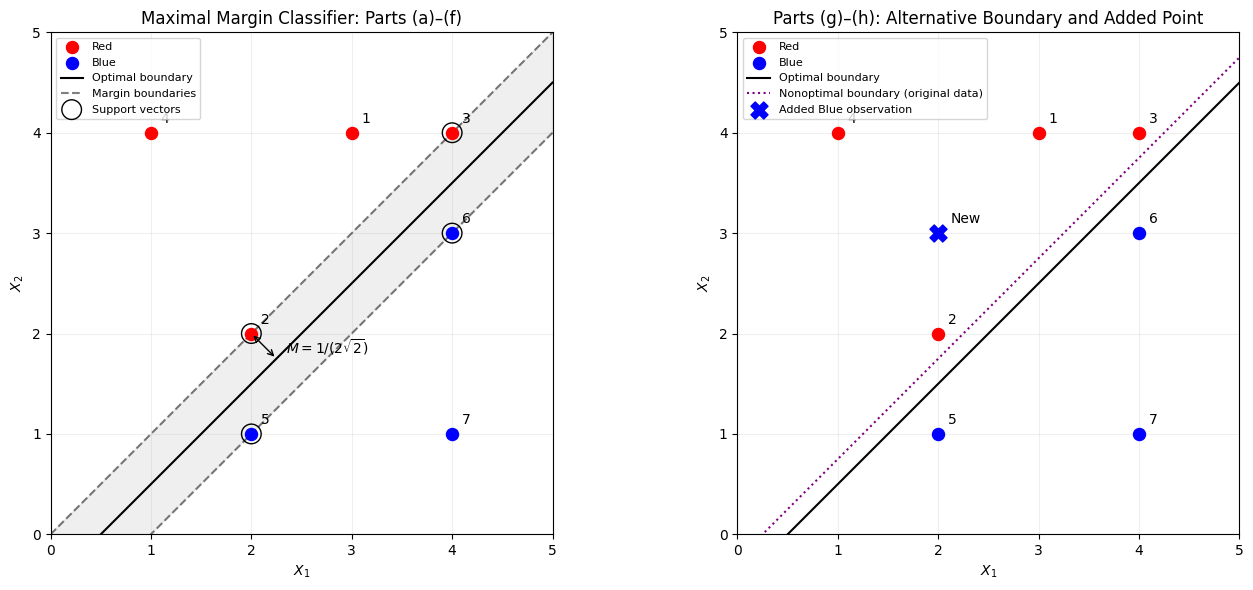

In [18]:
points = np.array([
    [3, 4],  # Observation 1: Red
    [2, 2],  # Observation 2: Red
    [4, 4],  # Observation 3: Red
    [1, 4],  # Observation 4: Red
    [2, 1],  # Observation 5: Blue
    [4, 3],  # Observation 6: Blue
    [4, 1]   # Observation 7: Blue
])

support_indices = [1, 2, 4, 5]
x = np.linspace(0, 5, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax in axes:
    ax.scatter(
        points[:4, 0], points[:4, 1],
        color="red", s=75, label="Red", zorder=3
    )
    ax.scatter(
        points[4:, 0], points[4:, 1],
        color="blue", s=75, label="Blue", zorder=3
    )

    for i, (x1, x2) in enumerate(points, start=1):
        ax.annotate(
            str(i), (x1, x2),
            xytext=(7, 7),
            textcoords="offset points"
        )

    ax.plot(x, x - 0.5, "k-", label="Optimal boundary")
    ax.set(
        xlim=(0, 5),
        ylim=(0, 5),
        xlabel="$X_1$",
        ylabel="$X_2$"
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

# Left: original data, support vectors, and margin.
ax = axes[0]

ax.plot(x, x, "k--", alpha=0.5, label="Margin boundaries")
ax.plot(x, x - 1, "k--", alpha=0.5)
ax.fill_between(x, x - 1, x, color="gray", alpha=0.12)

ax.scatter(
    points[support_indices, 0],
    points[support_indices, 1],
    s=200,
    facecolors="none",
    edgecolors="black",
    label="Support vectors",
    zorder=4
)

# Perpendicular distance from the boundary to observation 2.
ax.annotate(
    "",
    xy=(2, 2),
    xytext=(2.25, 1.75),
    arrowprops={"arrowstyle": "<->", "color": "black"}
)
ax.text(2.35, 1.8, r"$M=1/(2\sqrt{2})$")

ax.set_title("Maximal Margin Classifier: Parts (a)–(f)")
ax.legend(loc="upper left", fontsize=8)

# Right: alternative separator and added Blue observation.
ax = axes[1]

ax.plot(
    x, x - 0.25,
    color="purple",
    linestyle=":",
    label="Nonoptimal boundary (original data)"
)

ax.scatter(
    2, 3,
    color="blue",
    marker="X",
    s=150,
    label="Added Blue observation",
    zorder=5
)
ax.annotate(
    "New", (2, 3),
    xytext=(9, 7),
    textcoords="offset points"
)

ax.set_title("Parts (g)–(h): Alternative Boundary and Added Point")
ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()